# Telco Customer Churn: who is likely to leave, and how should retention be targeted?

**Business question:** a telecom provider wants to contact customers *before* they cancel. Which customers should the retention team call first, and what drives churn?

**Data:** [IBM Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), 7,043 customers, 20 attributes, label = churned in the last month.

**Approach**
1. Check and clean the data (with a reason for every decision)
2. Look at churn rates by the main business attributes
3. Compare three models with cross-validation, then confirm on a held-out test set
4. Translate the best model into a targeting decision: how many churners do we reach if we call the top 10 / 20 / 30 % riskiest customers?
5. Explain the drivers

In [1]:
%config InlineBackend.figure_formats = ["svg"]
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

matplotlib.rcParams["svg.fonttype"] = "none"   # charts keep text as text
SEED = 42
CHARTS = Path("images"); CHARTS.mkdir(exist_ok=True)
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781", "#e1e0d9"

def style(ax, title, subtitle=None):
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)

## 1. Load and check the data

In [2]:
df = pd.read_csv("data/telco_churn.csv")
print(df.shape)
print("Churn rate:", round((df["Churn"] == "Yes").mean() * 100, 1), "%")
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

(7043, 21)
Churn rate: 26.5 %
Duplicate customer IDs: 0


`TotalCharges` is stored as text and has blank values. Before filling them, check **who** these customers are:

In [3]:
total = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.loc[total.isna(), ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


All 11 blanks are customers with **tenure 0**: they joined this month and have not been billed yet. Their correct total is **0**, not the median (which would be about 1,400 and would make brand-new customers look like long-standing ones).

In [4]:
df["TotalCharges"] = total.fillna(0.0)
df["churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])

## 2. Where is churn concentrated?

In [5]:
def churn_by(col):
    t = df.groupby(col)["churn"].agg(customers="size", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t.sort_values("churn_rate", ascending=False)

df["tenure_group"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
for col in ["Contract", "tenure_group", "InternetService", "PaymentMethod"]:
    display(churn_by(col))
df = df.drop(columns=["tenure_group"])

,customers,churn_rate
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


,customers,churn_rate
tenure_group,,
0-12 m,2186,47.4
13-24 m,1024,28.7
25-48 m,1594,20.4
49-72 m,2239,9.5


,customers,churn_rate
InternetService,,
Fiber optic,3096,41.9
DSL,2421,19.0
No,1526,7.4


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


- Month-to-month customers churn far more than customers on one- or two-year contracts.
- Most churn happens in the first year.
- Fibre-optic customers and customers paying by electronic check churn more often.

These are correlations, not causes, but they tell the retention team where to look.

## 3. Compare models

In [6]:
X, y = df.drop(columns="churn"), df["churn"]
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

def make(model, scale):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

models = {
    "Logistic regression": make(LogisticRegression(max_iter=2000), scale=True),
    "Random forest": make(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1), scale=False),
    "Gradient boosting": make(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=SEED), scale=False),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in models.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    test_auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    rows.append({"model": name, "cv_auc_mean": cv_auc.mean().round(3), "cv_auc_sd": cv_auc.std().round(3),
                 "test_auc": round(test_auc, 3)})
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

/tmp/ipykernel_776/3280565418.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns.tolist()


,model,cv_auc_mean,cv_auc_sd,test_auc
0,Logistic regression,0.846,0.013,0.842
1,Random forest,0.845,0.010,0.841
2,Gradient boosting,0.834,0.007,0.828


The three models are within about 0.01 AUC of each other, and the cross-validation spread is of the same size. More complex models do **not** buy accuracy here, so **logistic regression is the better choice**: it is as accurate, simpler to run, and its coefficients can be explained to the business.

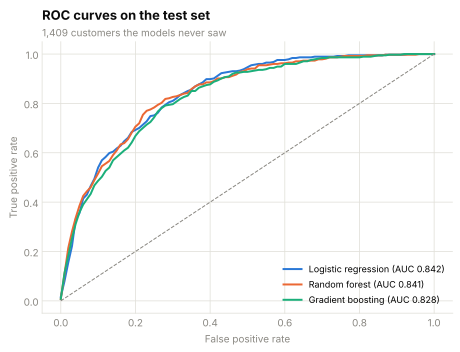

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (name, pipe), color in zip(models.items(), [BLUE, ORANGE, AQUA]):
    fpr, tpr, _ = roc_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    grid = np.linspace(0, 1, 101)                      # 101 points are enough to draw the curve
    fpr, tpr = grid, np.interp(grid, fpr, tpr)
    auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("False positive rate", color=MUTED); ax.set_ylabel("True positive rate", color=MUTED)
style(ax, "ROC curves on the test set", "1,409 customers the models never saw")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(CHARTS / "roc_curves.svg"); plt.show()

## 4. From a score to a decision

A retention team cannot call everyone. The useful question is: **if we call the top X % of customers by predicted risk, what share of all churners do we reach?**

In [8]:
best = models["Logistic regression"]
p = best.predict_proba(X_test)[:, 1]
order = np.argsort(-p)
captured = np.cumsum(y_test.to_numpy()[order]) / y_test.sum()
share = np.arange(1, len(p) + 1) / len(p)

targets = []
for pct in (10, 20, 30, 40):
    k = int(len(p) * pct / 100)
    targets.append({"contact_top_pct": pct, "customers_contacted": k,
                    "churners_reached_pct": round(captured[k - 1] * 100, 1),
                    "precision_pct": round(y_test.to_numpy()[order][:k].mean() * 100, 1)})
targeting = pd.DataFrame(targets)
targeting.to_csv(RESULTS / "targeting.csv", index=False)
print(f"Base churn rate in the test set: {y_test.mean():.1%}")
targeting

Base churn rate in the test set: 26.5%


,contact_top_pct,customers_contacted,churners_reached_pct,precision_pct
0,10,140,28.1,75.0
1,20,281,49.7,66.2
2,30,422,65.0,57.6
3,40,563,77.8,51.7


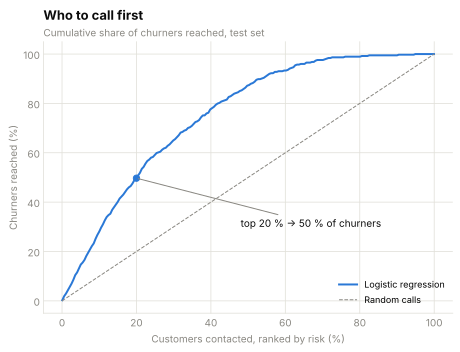

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 5))
step = max(1, len(share) // 200)                      # thin the line to ~200 points
ax.plot(share[::step] * 100, captured[::step] * 100, color=BLUE, linewidth=2, label="Logistic regression")
ax.plot([0, 100], [0, 100], color=MUTED, linestyle="--", linewidth=1, label="Random calls")
k20 = targeting.loc[targeting.contact_top_pct == 20].iloc[0]
ax.scatter([20], [k20.churners_reached_pct], color=BLUE, s=40, zorder=3)
ax.annotate(f"top 20 % → {k20.churners_reached_pct:.0f} % of churners", (20, k20.churners_reached_pct),
            xytext=(48, 30), fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xlabel("Customers contacted, ranked by risk (%)", color=MUTED)
ax.set_ylabel("Churners reached (%)", color=MUTED)
style(ax, "Who to call first", "Cumulative share of churners reached, test set")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(CHARTS / "targeting_curve.svg"); plt.show()

Choosing a probability cut-off is a business decision, not a modelling default. The table shows the trade-off between catching churners (recall) and wasting calls on customers who would have stayed (precision):

In [10]:
cut = []
for t in (0.3, 0.4, 0.5, 0.6):
    pred = (p >= t).astype(int)
    cut.append({"threshold": t, "flagged_customers": int(pred.sum()),
                "recall_pct": round(recall_score(y_test, pred) * 100, 1),
                "precision_pct": round(precision_score(y_test, pred) * 100, 1)})
thresholds = pd.DataFrame(cut)
thresholds.to_csv(RESULTS / "thresholds.csv", index=False)
thresholds

,threshold,flagged_customers,recall_pct,precision_pct
0,0.3,543,75.4,51.9
1,0.4,440,66.8,56.8
2,0.5,319,56.1,65.8
3,0.6,209,40.1,71.8


## 5. What drives churn in the model?

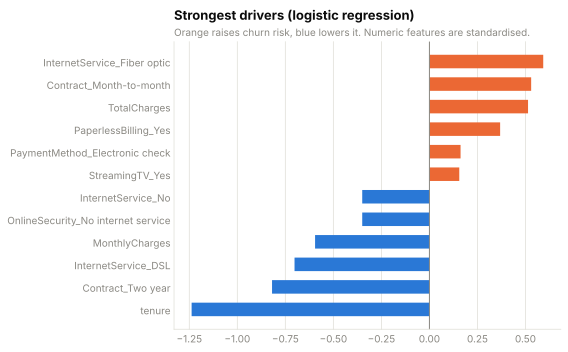

In [11]:
names = best.named_steps["prep"].get_feature_names_out()
coef = pd.Series(best.named_steps["model"].coef_[0], index=[n.split("__", 1)[1] for n in names])
drivers = pd.concat([coef.nlargest(6), coef.nsmallest(6)]).sort_values()
drivers.rename("coefficient").round(3).to_csv(RESULTS / "drivers.csv")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(drivers.index, drivers.values, color=[ORANGE if v > 0 else BLUE for v in drivers.values], height=0.6)
ax.axvline(0, color=MUTED, linewidth=1)
ax.tick_params(axis="y", colors=INK)
style(ax, "Strongest drivers (logistic regression)", "Orange raises churn risk, blue lowers it. Numeric features are standardised.")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(CHARTS / "drivers.svg"); plt.show()

**Reading the drivers:** short tenure, month-to-month contracts and fibre-optic internet push risk up; long contracts and longer tenure push it down. Several of these features overlap (for example tenure and total charges), so individual coefficients should be read as directions, not exact effect sizes.

## Recommendations

1. **Target the top 20 % by risk** for retention calls: this reaches most churners with a fraction of the effort (see table above).
2. **Offer contract upgrades in the first months**: churn is concentrated in early, month-to-month customers.
3. **Look into the fibre-optic experience**: high churn despite a premium product suggests price or service problems worth investigating.

## Limitations

- One snapshot in time; no information about *when* in the month customers left.
- Correlation, not causation: a retention offer should be tested with a control group before rolling it out.
- The dataset is a public sample; a real deployment would need monitoring for drift and re-training.